# 大模型微调 07：基于 GPT-2 搭建医疗问诊机器人

本篇按课程的“项目背景 → 数据介绍 → 数据处理 → 模型搭建 → 训练与验证 → 人机交互”顺序，整理本地所有 `07` 开头文件夹。第 06 篇已有项目概览，本篇补齐完整训练代码、因果语言模型的错位监督、命令行生成和 Flask 页面调用。

来源包括 18 页 PDF 讲义、22 页课件、`Gpt2_Chatbot` 工程及附属资料。附属资料中的 `Global_Pointer` 是另一个医学实体识别工程，放在末尾单独整理；它没有在当前 GPT-2 调用链中使用。

阅读目标是能说明数据如何变成模型输入、loss 如何计算、参数何时更新、checkpoint 如何使用，以及每个回复 token 如何生成。笔记中的代码供阅读和复现参考，本次未执行模型训练或启动服务。

## 一、项目背景与整体结构

课程先介绍聊天机器人在客服、个人助手、语言学习等场景中的用途，再把任务限定为医疗领域的对话生成：给定用户问题和对话上下文，由 GPT-2 继续生成回答。

项目包含数据处理、模型构建、模型评估和交互应用。评估除了训练指标，也包括实际回复的人工检查。讲义以小冰、小蜜、小度作为聊天产品的示例，核心实现不依赖这些产品。

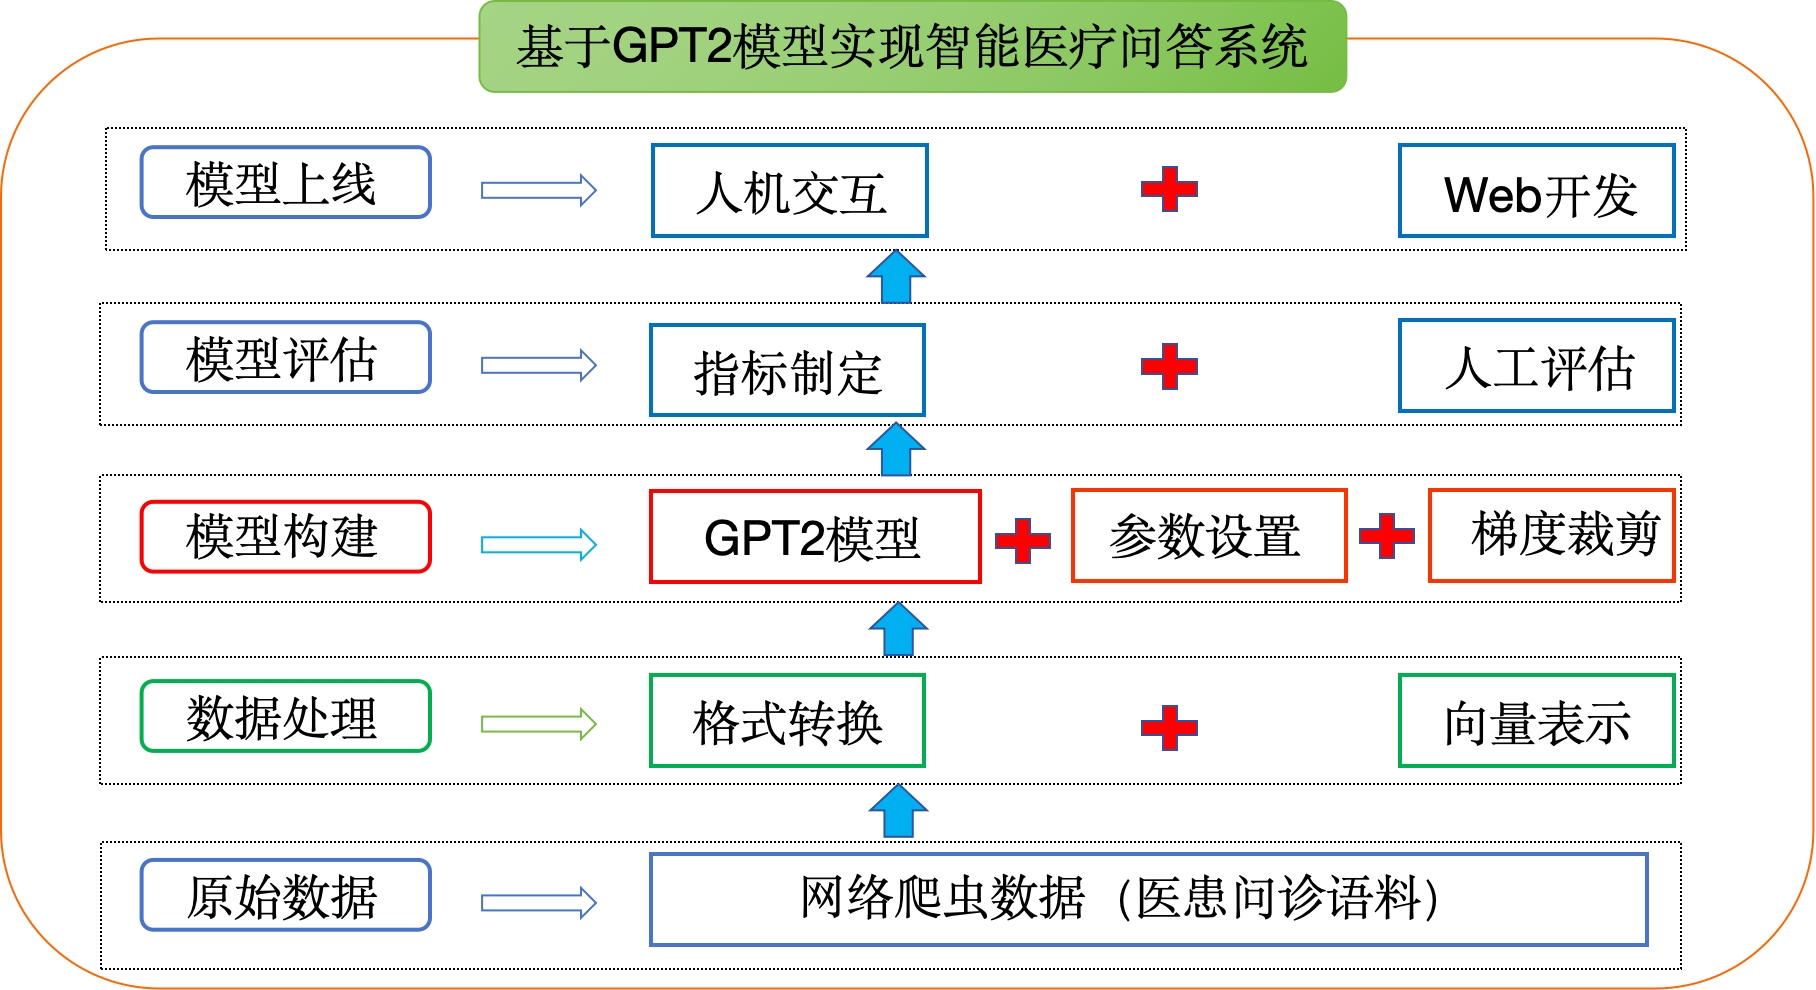

### 1.1 文件与调用关系

本地工程根目录是 `D:\baidudisk\BaiduNetdiskDownload\07-代码\Gpt2_Chatbot`。

| 文件或目录 | 本节作用 |
| --- | --- |
| `data/medical_train.txt`、`medical_valid.txt` | 原始训练与验证对话 |
| `data_preprocess/preprocess.py` | 拼特殊 token，生成 `.pkl` |
| `data_preprocess/dataset.py`、`dataloader.py` | 截断、补齐和批量读取 |
| `parameter_config.py`、`config/config.json` | 运行参数与 GPT-2 结构 |
| `functions_tools.py` | next-token loss 和 token accuracy |
| `train.py` | 单轮训练、验证、总训练及主入口 |
| `save_model/epoch97` | 下载资料自带的已训练 checkpoint |
| `interact.py` | 命令行保留历史的对话 |
| `flask_predict.py`、`app.py`、`templates/index.html` | 网页问答 |
| `pytorch_tools.py` | 附带 EarlyStopping，当前训练入口未调用 |
| `review.py`、`test_model.py` | 张量操作与模型结构练习 |
| `other_data/闲聊语料.txt` | 备用语料，当前训练入口没有读取 |

附属资料另带的 `save_model/epoch97` 与工程内同名模型权重经哈希比对相同，可视为同一份 checkpoint 的副本。

### 1.2 环境记录与运行位置

PDF 记录的环境是 Python 3.6、`transformers==4.2.0`、PyTorch 1.7.0；课件记录的是 Python ≥ 3.8、Transformers ≥ 4.2.0、PyTorch ≥ 1.7.0。两份资料的版本写法不同，这是原始课程记录，不能据此认为所有更新版本都兼容。

代码还导入 `tqdm`，网页部分使用 Flask。`transformers.AdamW` 等接口与版本有关，复现时先核对环境，再处理相应导入，不在本笔记中切换另一套训练框架。

后续命令默认在工程根目录运行：

```powershell
Set-Location -LiteralPath 'D:\baidudisk\BaiduNetdiskDownload\07-代码\Gpt2_Chatbot'
```

源文件保留作者机器上的 `/Users/ligang/...` 路径，需要替换为本机对应位置。讲义曾把 `train.py` 写在 `data_preprocess` 下，实际下载版的训练入口在工程根目录，以实际文件为准。

## 二、数据介绍：先确定一段对话的边界

每段对话内部以换行分隔 utterance（一次发言），段与段之间用空行分隔。两行可以构成一问一答；同一段中也可继续追加多次发言，构成多轮对话。

原文件的格式示例：

```text
帕金森叠加综合征的辅助治疗有些什么？
综合治疗；康复训练；生活护理指导；低频重复经颅磁刺激治疗

卵巢癌肉瘤的影像学检查有些什么？
超声漏诊；声像图；MR检查；肿物超声；术前超声；CT检查
```

这里展示的是训练语料格式，模型没有额外的角色字段；发言顺序和 `[SEP]` 共同表达上下文。

### 2.1 资料数量与本地文件数量

PDF 写训练数据 91487 条、验证数据 1244 条，课件则写“约 3 万对聊天记录”。对当前下载的文本实际统计如下，统计时排除空块：

| 文件 | 非空文本行 | 按空行分开的非空对话块 |
| --- | ---: | ---: |
| `medical_train.txt` | 61219 | 30162 |
| `medical_valid.txt` | 831 | 413 |

当前文件的对话块数量与课件的约 3 万对接近。PDF 的“条数”与当前统计不同，原资料未提供统一口径，不能直接作为当前 Dataset 的长度。训练使用 `.pkl`，若没有重新预处理，还需要实际检查 `.pkl` 的条数。

## 三、数据处理：从文本到 token ID

课程分为格式转换、tokenize、Dataset、DataLoader 四步。当前数据已经是目标 txt 格式，因此没有实现图中的 `data_format_convert.py`，从 `preprocess.py` 开始。

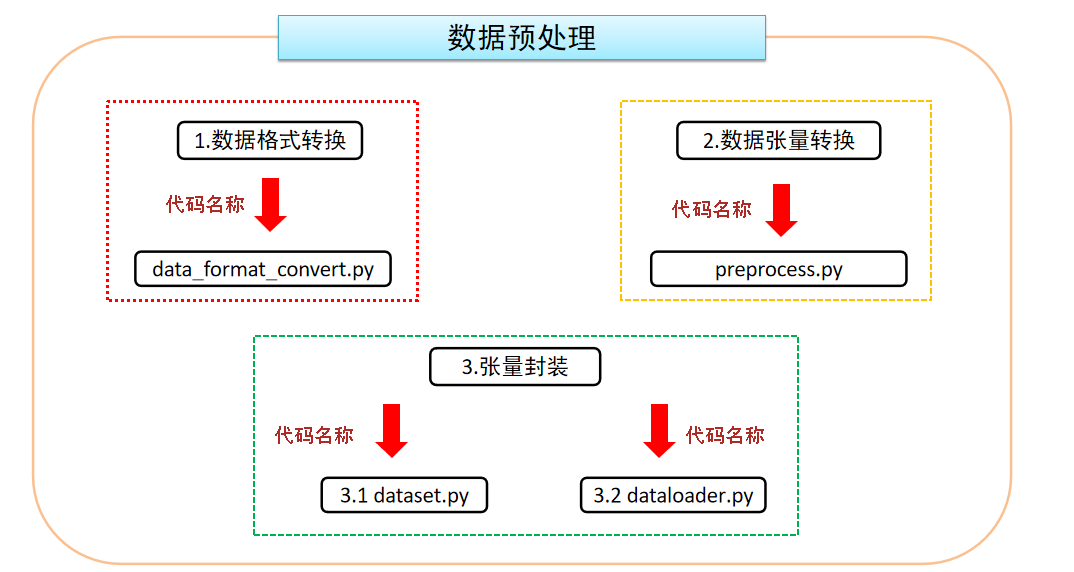

### 3.1 每段对话的编码格式

```text
[CLS] 问题1 [SEP] 回答1 [SEP] 问题2 [SEP] 回答2 [SEP]
```

`BertTokenizerFast` 在这里仅负责中文切词和 token ID 转换，后面的语言模型仍然是 GPT-2。

| token | 当前 `vocab/vocab.txt` 中的 ID | 用途 |
| --- | ---: | --- |
| `[PAD]` | 0 | batch 内补齐 |
| `[UNK]` | 100 | 词表外 token；生成时禁止采样 |
| `[CLS]` | 101 | 一段对话的开始 |
| `[SEP]` | 102 | 发言分隔，生成时也是回复终止标记 |

源码手工添加特殊 token，所以对每句调用 `encode(..., add_special_tokens=False)`，避免重复添加 `[CLS]` 和 `[SEP]`。处理结果 `dialogue_list` 是 `List[List[int]]`，pickle 只是序列化保存，此时还没有变成 PyTorch Tensor。

源码：`07-代码/Gpt2_Chatbot/data_preprocess/preprocess.py`（节选）。

```python
def data_preprocess(train_txt_path, train_pkl_path):
    """
    对原始语料进行tokenizer，将每段对话处理成如下形式："[CLS]sentence1[SEP]sentence2[SEP]sentence3[SEP]"
    """

    # 初始化tokenizer，使用BertTokenizerFast从预训练的中文Bert模型（bert-base-chinese）创建一个tokenizer对象
    # tokenizer = BertTokenizerFast.from_pretrained('/Users/ligang/PycharmProjects/llm/prompt_tasks/bert-base-chinese',
    #                                         )

    tokenizer = BertTokenizerFast('/Users/ligang/PycharmProjects/llm/Gpt2_Chatbot/vocab/vocab.txt',
                                                  sep_token="[SEP]",
                                                  pad_token="[PAD]",
                                                  cls_token="[CLS]")


    print(f'tokenizer.vocab_size-->{tokenizer.vocab_size}')

    sep_id = tokenizer.sep_token_id  # 获取分隔符[SEP]的token ID
    cls_id = tokenizer.cls_token_id  # 获取起始符[CLS]的token ID
    print(f'sep_id-->{sep_id}')
    print(f'cls_id-->{cls_id}')
    # #
    #
    # # 读取训练数据集
    with open(train_txt_path, 'rb') as f:
        data = f.read().decode("utf-8")  # 以UTF-8编码读取文件内容
    # print(data)
    # # # # # 根据换行符区分不同的对话段落，需要区分Windows和Linux\mac环境下的换行符
    if "\r\n" in data:
        train_data = data.split("\r\n\r\n")
    else:
        train_data = data.split("\n\n")
    # #
    print(len(train_data))  # 打印对话段落数量
    print(train_data[:2])
    # # # # # 开始进行tokenize
    # # # # # 保存所有的对话数据,每条数据的格式为："[CLS]seq1[SEP]seq2[SEP]seq3[SEP]"
    dialogue_len = []  # 记录所有对话tokenize分词之后的长度，用于统计中位数与均值
    dialogue_list = []  # 记录所有对话
    # # # # #
    for index, dialogue in enumerate(tqdm(train_data)):
        # print(f'dialogue-->{dialogue}')
        if "\r\n" in dialogue:
            sequences = dialogue.split("\r\n")
        else:
            sequences = dialogue.split("\n")
        # print(f'sequences--》{sequences}')

        input_ids = [cls_id]  # 每个dialogue以[CLS]seq1[sep]seq2[sep]
        for sequence in sequences:

            input_ids += tokenizer.encode(sequence, add_special_tokens=False)  # 将每个对话句子进行tokenize，并将结果拼接到input_ids列表中
            # input_ids += tokenizer.encode(sequence)  # 将每个对话句子进行tokenize，并将结果拼接到input_ids列表中
            input_ids.append(sep_id)  # 每个seq之后添加[SEP]，表示seqs会话结束

        dialogue_len.append(len(input_ids))  # 将对话的tokenize后的长度添加到对话长度列表中
        dialogue_list.append(input_ids)  # 将tokenize后的对话添加到对话列表中

    # # # # 保存数据
    with open(train_pkl_path, "wb") as f:
        pickle.dump(dialogue_list, f)
```

### 3.2 训练集和验证集都要预处理

下载版函数名为 `data_preprocess()`，文件末尾默认只处理验证集，并使用相对路径 `../data/...`。如果从工程根目录运行，应传入与根目录对应的路径。下面是基于原函数的调用示例：

```python
from data_preprocess.preprocess import data_preprocess

data_preprocess("data/medical_train.txt", "data/medical_train.pkl")
data_preprocess("data/medical_valid.txt", "data/medical_valid.pkl")
```

调用前先改好函数内硬编码的 `vocab.txt` 路径。成功后应生成两个 `.pkl`；可以在可信的课程数据上加载，查看列表长度、首条序列，以及首尾的特殊 token。原函数没有显式清理空段，实际结果长度还可能包含末尾空段，不能把文本统计硬写成 `.pkl` 长度。

### 3.3 Dataset：按最大长度截断

`MyDataset.__getitem__()` 取出一段 token ID 序列，截取前 `max_len` 个 token，再转换为 `torch.long`。这一步只截断，不负责 padding。默认 `max_len=300`。

截断会直接丢掉后面的 token，包括可能的尾部 `[SEP]`，所以长度设置会影响模型可见的回答内容。

源码：`07-代码/Gpt2_Chatbot/data_preprocess/dataset.py`（节选）。

```python
class MyDataset(Dataset):
    """
    自定义数据集类，继承自Dataset类
    """
    def __init__(self, input_list, max_len):
        super().__init__()
        """
        初始化函数，用于设置数据集的属性
        :param input_list: 输入列表，包含所有对话的tokenize后的输入序列
        :param max_len: 最大序列长度，用于对输入进行截断或填充
        """
        # print(f'input_list--->{len(input_list)}')
        self.input_list = input_list  # 将输入列表赋值给数据集的input_list属性
        self.max_len = max_len  # 将最大序列长度赋值给数据集的max_len属性

    def __len__(self):
        """
        获取数据集的长度
        :return: 数据集的长度
        """
        return len(self.input_list)  # 返回数据集的长度

    def __getitem__(self, index):
        """
        根据给定索引获取数据集中的一个样本
        :param index: 样本的索引
        :return: 样本的输入序列张量
        """
        # print(f'当前取出的索引是--》{index}')
        input_ids = self.input_list[index]  # 获取给定索引处的输入序列
        # print(f'input_ids--》{input_ids}')
        input_ids = input_ids[:self.max_len]  # 根据最大序列长度对输入进行截断或填充
        input_ids = torch.tensor(input_ids, dtype=torch.long)  # 将输入序列转换为张量long类型
        return input_ids  # 返回样本的输入序列张量
```

### 3.4 DataLoader：输入和标签分别补齐

`collate_fn()` 对同一 batch 的序列补到该 batch 的最长长度：

```text
input_ids: [CLS] ... [SEP] [PAD] [PAD]    补齐值 0
labels:    [CLS] ... [SEP] -100  -100     补齐值 -100
```

两者真实位置的 token ID 一样；区别在 padding。`-100` 使补齐位置不参与交叉熵损失和 token accuracy。源码没有把 labels 提前移一位，错位监督由 GPT-2 内部完成。

两个 DataLoader 都设置了 `shuffle=True`、`drop_last=True`，batch size 从配置中读取，默认 4。验证集也会丢掉最后不足一批的样本，且打乱顺序；解释验证结果时要记住这个原实现细节。

源码：`07-代码/Gpt2_Chatbot/data_preprocess/dataloader.py`。

```python
# -*- coding: utf-8 -*-
import torch.nn.utils.rnn as rnn_utils  # 导入rnn_utils模块，用于处理可变长度序列的填充和排序
from torch.utils.data import Dataset, DataLoader  # 导入Dataset和DataLoader模块，用于加载和处理数据集
import torch  # 导入torch模块，用于处理张量和构建神经网络
import pickle  # 导入pickle模块，用于序列化和反序列化Python对象
from dataset import *  # 导入自定义的数据集类
from parameter_config import *

params = ParameterConfig()

def load_dataset(train_path, valid_path):
    # print('进入函数')
    """
    加载训练集和验证集
    :param train_path: 训练数据集路径
    :return: 训练数据集和验证数据集
    """
    with open(train_path, "rb") as f:
        train_input_list = pickle.load(f)  # 从文件中加载输入列表

    with open(valid_path, "rb") as f:
        valid_input_list = pickle.load(f)  # 从文件中加载输入列表
    # 划分训练集与验证集
    # print(len(train_input_list))  # 打印输入列表的长度
    # print(train_input_list[0])
    #
    train_dataset = MyDataset(train_input_list, params.max_len)  # 创建训练数据集对象
    val_dataset = MyDataset(valid_input_list, params.max_len)  # 创建验证数据集对象
    return train_dataset, val_dataset  # 返回训练数据集和验证数据集

def collate_fn(batch):
    """
    自定义的collate_fn函数，用于将数据集中的样本进行批处理
    :param batch: 样本列表
    :return: 经过填充的输入序列张量和标签序列张量
    """
    # print(f'batch-->{batch}')
    # print(f'batch的长度-->{len(batch)}')
    # print(f'batch的第一个样本的长度--》{batch[0].shape}')
    # print(f'batch的第二个样本的长度--》{batch[1].shape}')
    # print(f'batch的第三个样本的长度--》{batch[2].shape}')
    # print(f'batch的第四个样本的长度--》{batch[3].shape}')
    # print(f'*'*80)
    #rnn_utils.pad_sequence：将根据一个batch中，最大句子长度，进行补齐
    input_ids = rnn_utils.pad_sequence(batch, batch_first=True, padding_value=0)  # 对输入序列进行填充，使其长度一致
    # print(f'batch的第一个样本的长度--》{input_ids[0].shape}')
    # print(f'batch的第二个样本的长度--》{input_ids[1].shape}')
    # print(f'batch的第三个样本的长度--》{input_ids[2].shape}')
    # print(f'batch的第四个样本的长度--》{input_ids[3].shape}')
    labels = rnn_utils.pad_sequence(batch, batch_first=True, padding_value=-100)  # 对标签序列进行填充，使其长度一致
    # # print(f'labels-->{labels}')
    return input_ids, labels  # 返回经过填充的输入序列张量和标签序列张量


def get_dataloader(train_path, valid_path):
    """
    获取训练数据集和验证数据集的DataLoader对象
    :param train_path: 训练数据集路径
    :return: 训练数据集的DataLoader对象和验证数据集的DataLoader对象
    """

    train_dataset, val_dataset = load_dataset(train_path, valid_path)  # 加载训练数据集和验证数据集
    # print(f'train_dataset-->{len(train_dataset)}')
    # print(f'val_dataset-->{len(val_dataset)}')
    train_dataloader = DataLoader(train_dataset,
                                  batch_size=params.batch_size,
                                  shuffle=True,
                                  collate_fn=collate_fn,
                                  drop_last=True)  # 创建训练数据集的DataLoader对象
    validate_dataloader = DataLoader(val_dataset,
                                     batch_size=params.batch_size,
                                     shuffle=True,
                                     collate_fn=collate_fn,
                                     drop_last=True)  # 创建验证数据集的DataLoader对象
    return train_dataloader, validate_dataloader  # 返回训练数据集的DataLoader对象和验证数据集的DataLoader对象


if __name__ == '__main__':
    train_dataloader, validate_dataloader = get_dataloader(params.train_path, params.valid_path)
    for input_ids, labels in train_dataloader:
        print(f'input_ids--》{input_ids.shape}')
        print(f'labels--》{labels.shape}')
        break
```

### 3.5 下载版中的导入路径差异

`data_preprocess/dataloader.py` 写的是 `from dataset import *`。从工程根目录启动 `train.py` 时，这个顶层导入可能找不到同文件夹的 `dataset.py`。按当前包结构，复现时可把该行改为：

```python
from data_preprocess.dataset import MyDataset
```

上面的源码块仍保留原文件；这是为匹配当前目录结构所需的调整。修改配置与导入后，可在根目录运行：

```powershell
python -m data_preprocess.dataloader
```

文件末尾会打印一个 batch 的 `input_ids.shape` 和 `labels.shape`。二者应相同，形状为 `(batch_size, 当前批最长长度)`，第二维不超过 300，不应强行假设每批都恰好是 300。

## 四、模型搭建与配置

课件的结构是词嵌入加位置嵌入，经过 12 层 Transformer Decoder，再由最终 LayerNorm 和语言模型输出层给出词表 logits。Decoder 使用因果遮罩，当前位置只能利用前面的 token 预测下一个 token。

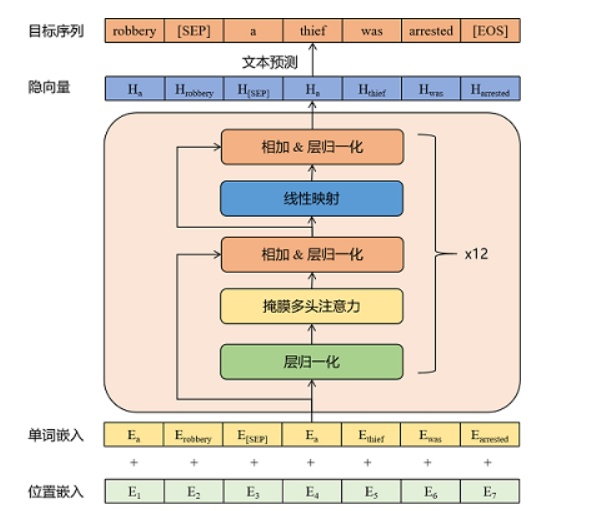

### 4.1 结构配置

| 字段 | 下载版配置值 | 含义 |
| --- | ---: | --- |
| `n_embd` | 768 | 隐藏向量维度 |
| `n_head` | 12 | 注意力头数 |
| `n_layer` | 12 | Decoder 层数 |
| `n_positions` / `n_ctx` | 1024 | 位置和上下文配置 |
| `vocab_size` | 13317 | 模型输入/输出词表大小 |
| `activation_function` | `gelu_new` | 激活函数 |
| `attn_pdrop`、`embd_pdrop`、`resid_pdrop` | 0.1 | dropout |

课件也提到可用 21128 词表，当前工程实际同时提供 `vocab.txt`（13317 项）和 `vocab2.txt`（21128 项）。默认模型及 `epoch97` 都配置为 13317，不能直接替换成另一词表。除了大小一致，词到 ID 的顺序也必须与 checkpoint 一致。

配置里还保留 `bos_token_id=eos_token_id=50256`，这是超出当前词表的默认值；本工程的手写生成循环使用 tokenizer 的 `[CLS]` / `[SEP]`，没有依赖这两个配置字段。若切换到基于这些字段的生成入口，需要先核对特殊 token 配置。

源码：`07-代码/Gpt2_Chatbot/config/config.json`。

```json
{
  "activation_function": "gelu_new",
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "gradient_checkpointing": false,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 12,
  "n_positions": 1024,
  "output_past": true,
  "resid_pdrop": 0.1,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 400
    }
  },
  "tokenizer_class": "BertTokenizer",
  "transformers_version": "4.2.0",
  "use_cache": true,
  "vocab_size": 13317
}
```

### 4.2 “加载预训练权重”与“只使用 GPT-2 结构”

源码有两个分支：

```python
if params.pretrained_model:
    model = GPT2LMHeadModel.from_pretrained(params.pretrained_model)
else:
    model_config = GPT2Config.from_json_file(params.config_json)
    model = GPT2LMHeadModel(config=model_config)
```

讲义将本项目描述为使用预训练模型，但下载版 `ParameterConfig.pretrained_model=''`，默认进入第二个分支，按结构随机初始化参数。**仅传入 `GPT2Config` 不会加载预训练权重。**已有 `save_model/epoch97` 可以在交互阶段加载，不能据此认为默认训练入口也读取了它。

主入口还通过 `assert model.config.vocab_size == tokenizer.vocab_size` 检查词表大小，并统计参数总量。这里使用的是完整模型参数优化，资料没有实现 LoRA 或其他参数高效微调模块。

### 4.3 训练与生成参数

| 参数 | 下载版默认值 | 作用 |
| --- | ---: | --- |
| `device` | CUDA 可用则 CUDA，否则 CPU | 模型和输入放在同一设备 |
| `batch_size` | 4 | 单个 batch 的对话数 |
| `epochs` | 4 | 训练轮数 |
| `lr` / `eps` | `2.6e-5` / `1e-9` | AdamW 参数 |
| `gradient_accumulation_steps` | 4 | 累积 4 批梯度再更新 |
| `max_grad_norm` | 4.0 | 梯度裁剪上限 |
| `warmup_steps` | 100 | 学习率预热的更新步数 |
| `loss_step` | 1 | 每批打印一次训练信息 |
| `ignore_index` | -100 | 忽略标签 padding |
| `max_len` | 300 | Dataset 截断长度，同时用于生成循环上限 |
| `max_history_len` | 3 | 输入模型的最近 3 次发言 |
| `topk` | 4 | 采样候选限制 |
| `repetition_penalty` | 10.0 | 原生成代码中的重复 token 调整系数 |

`max_history_len=3` 计数的是 utterance，用户和机器人各算一次，不等于三组完整问答。单卡下，4 批、每批 4 段对话，通常可把一次参数更新理解为累计了 16 段对话的梯度。

源码：`07-代码/Gpt2_Chatbot/parameter_config.py`。

```python
#-*- coding: utf-8 -*-
import torch

class ParameterConfig():
    def __init__(self):
        # 判断是否使用GPU（1.电脑里必须有显卡；2.必须安装cuda版本的pytorch）
        # 下载cuda版本的pytorch链接：https://pytorch.org/get-started/previous-versions/
        # self.device = 'mps'
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        # 词典路径：在vocab文件夹里面
        self.vocab_path = '/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/vocab/vocab.txt'
        # 训练文件路径
        self.train_path = '/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/data/medical_train.pkl'
        # 验证数据文件路径
        self.valid_path = '/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/data/medical_valid.pkl'
        # 模型配置文件
        self.config_json = '/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/config/config.json'
        # 模型保存路径
        self.save_model_path = '/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/save_model1'
        # 如果你有预训练模型就写上路径（我们本次没有直接运用GPT2预训练好的模型，而是仅只用了该模型的框架）
        self.pretrained_model = ''
        # 保存对话语料
        self.save_samples_path = '/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/sample'
        # 忽略一些字符：句子需要长度补齐，针对补的部分，没有意义，所以一般不进行梯度更新
        self.ignore_index = -100
        # 历史对话句子的长度
        self.max_history_len = 3 # "dialogue history的最大长度"
        # 每一个完整对话的句子最大长度
        self.max_len = 300  # '每个utterance的最大长度,超过指定长度则进行截断,默认25'
        self.repetition_penalty = 10.0 # "重复惩罚参数，若生成的对话重复性较高，可适当提高该参数"
        self.topk = 4 #'最高k选1。默认8'
        self.batch_size = 4 #一个批次几个样本
        self.epochs = 4 # 训练几轮
        self.loss_step = 1 # 多少步汇报一次loss
        self.lr = 2.6e-5
        # eps，为了增加数值计算的稳定性而加到分母里的项，其为了防止在实现中除以零
        self.eps = 1.0e-09
        self.max_grad_norm = 4.0
        self.gradient_accumulation_steps = 4
        # 默认.warmup_steps = 4000
        self.warmup_steps = 100 # 使用Warmup预热学习率的方式,即先用最初的小学习率训练，然后每个step增大一点点，直到达到最初设置的比较大的学习率时（注：此时预热学习率完成），采用最初设置的学习率进行训练（注：预热学习率完成后的训练过程，学习率是衰减的），有助于使模型收敛速度变快，效果更佳。


if __name__ == '__main__':
    pc = ParameterConfig()
    print(pc.train_path)
    print(pc.device)
    print(torch.cuda.device_count())
```

## 五、模型训练与验证

训练代码把 GPT-2 内置 loss、工具函数统计、优化器、调度器、验证和模型保存连起来。

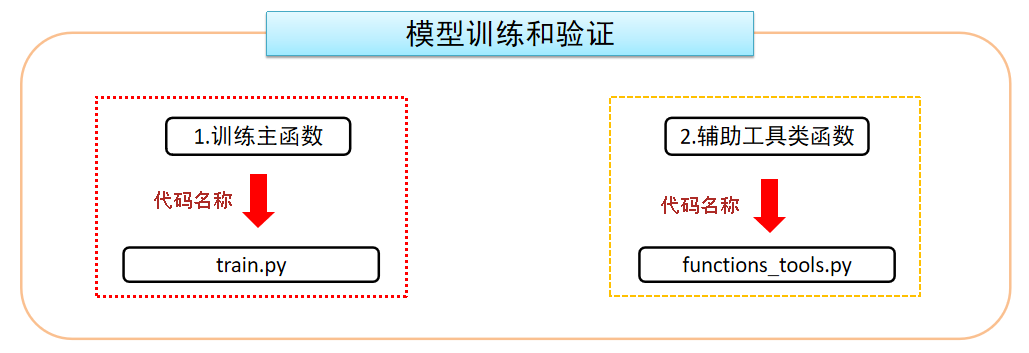

### 5.1 为什么 logits 与 labels 要错开一位

给定 `[CLS] A B [SEP]`，自回归训练的监督关系是：

```text
用于预测的输入位置：[CLS]  A   B
应预测的下一个词：   A    B  [SEP]
```

因此计算时取 `logits[:, :-1, :]` 与 `labels[:, 1:]`，展平后做交叉熵，忽略 `-100`。输出 logits 的原始形状是 `(B, L, V)`，移位后有 `B*(L-1)` 个预测位置。

`model(input_ids, labels=labels)` 已在模型内部计算这种因果语言模型 loss；无需再把 `caculate_loss()` 叠加一次。`caculate_loss` 是原文件中的拼写，用于解释或手工复现损失计算。

源码的 `calculate_acc()` 同样移位后取 argmax，只统计非 padding token。这个值是 token 预测准确率，不是整条问答正确率。

源码：`07-代码/Gpt2_Chatbot/functions_tools.py`（节选）。

```python
def caculate_loss(logit, target, pad_idx):
    '''
    计算模型的损失：通过函数解析下，GPT2内部如何计算损失的
    :param logit: 模型预测结果
    :param target: 真实标签
    :param pad_idx:特殊-100忽略计算损失的值
    :return:
    '''
    # loss = F.cross_entropy(predict_logit, target, ignore_index=pad_idx)
    logit = logit[..., :-1, :].contiguous().view(-1, logit.size(-1))
    labels = target[..., 1:].contiguous().view(-1)
    loss = F.cross_entropy(logit, labels, ignore_index=pad_idx)
    return loss


def calculate_acc(logit, labels, ignore_index=-100):
    # print(f'logit--->原始值的形状{logit.shape}')
    # print(f'labels--->原始值的形状{labels.shape}')
    # print(f' logit.size---{logit.size(-1)}')
    # print(f' logit[:, :-1, :]---{logit[:, :-1, :].shape}')
    logit = logit[:, :-1, :].contiguous().view(-1, logit.size(-1))
    # print(f'logit改变完形状的--->{logit.shape}')
    # print(f'labels[:, 1:]--->{labels[:, 1:].shape}')
    labels = labels[:, 1:].contiguous().view(-1)
    # print(f'labels真实标签--->{labels.shape}')
    # logit.max(dim=-1)：对每个预测单词，取出最大概率值以及对应索引
    _, logit = logit.max(dim=-1)  # 对于每条数据，返回最大的index
    # print(f'_-->{_}')
    # print(f'logit取出模型预测最大索引值-->{logit}')
    # print(f'logit预测结果---》{logit.shape}')
    '''
    在 PyTorch 中，labels.ne(ignore_index) 表示将标签张量 labels 中的值不等于 ignore_index 的位置标记为 True，等于 ignore_index 的位置标记为 False。
    这个操作，以过滤掉 ignore_index 对损失的贡献
    '''
    # 进行非运算，返回一个tensor，若labels的第i个位置为pad_id，则置为0，否则为1
    non_pad_mask = labels.ne(ignore_index)
    # print(f'non_pad_mask-->{non_pad_mask}')
    '''
    在 PyTorch 中，logit.eq(labels) 表示将模型的预测输出值 logit 中等于标签张量 labels 的位置标记为 True，
    不等于标签张量 labels 的位置标记为 False。以标记出预测输出值和标签值相等的位置。
    masked_select(non_pad_mask) 表示将张量中非填充标记的位置选出来。
    '''
    # print(f'logit.eq(labels)--->{ logit.eq(labels)}')
    # print(f'logit.eq(labels)--->{logit.eq(labels).shape}')
    n_correct = logit.eq(labels).masked_select(non_pad_mask).sum().item()
    # print(f'n_correct-->{n_correct}')
    n_word = non_pad_mask.sum().item()
    # print(f'non_pad_mask.sum()-->{non_pad_mask.sum()}')
    return n_correct, n_word
```

> 原 `readme` 说前向内部包含“反向传播”，这与当前训练代码不符：前向返回 logits 和 loss，调用 `loss.backward()` 才执行反向传播，`optimizer.step()` 才更新参数。

当前 labels 覆盖整段非 padding 对话，包括问题和回答；代码没有额外实现“仅对机器人回答计算 loss”的角色遮罩。

### 5.2 `train_epoch()`：一轮训练

每批依次完成：

1. `model.train()`，把输入与 labels 放到同一设备；
2. 前向读取 `outputs.logits`、`outputs.loss`；
3. 统计当前 batch 和 epoch 的有效 token accuracy；
4. 先记录未缩放 loss，再把用于反向的 loss 除以梯度累积步数；
5. `loss.backward()` 后裁剪梯度；
6. 满 4 批时更新参数、推进 scheduler、清空梯度；
7. 打印 batch loss、batch accuracy 和学习率；
8. 汇总 epoch 平均 batch loss 与整体有效 token accuracy。

注意两个计数不同：一次 batch 前向不是一次参数更新，scheduler 随 optimizer 更新推进。原实现每个 micro-batch 都执行梯度裁剪，而非只在累计完毕时裁剪。

源码：`07-代码/Gpt2_Chatbot/train.py`（节选）。

```python
def train_epoch(model,
                train_dataloader,
                optimizer, scheduler,
                epoch, args):
    '''
    :param model: GPT2模型
    :param train_dataloader: 训练数据集
    :param optimizer: 优化器：更新参数
    :param scheduler: 学习率预热
    :param epoch: 当前的轮次
    :param args: 模型配置文件的参数对象
    :return:
    '''
    # 1.指明模型训练
    model.train()
    device = args.device
    # 对于ignore_index的label token不计算梯度
    ignore_index = args.ignore_index
    epoch_start_time = datetime.now()
    total_loss = 0  # 记录下整个epoch的loss的总和

    # epoch_correct_num:每个epoch中,output预测正确的word的数量
    # epoch_total_num: 每个epoch中,output预测的word的总数量
    epoch_correct_num, epoch_total_num = 0, 0

    for batch_idx, (input_ids, labels) in enumerate(tqdm(train_dataloader)):
        input_ids = input_ids.to(device)
        # print(input_ids.shape)
        labels = labels.to(device)
        # print(f'input_ids-->{input_ids.shape}')
        # print(f'labels-->{labels.shape}')
        # print(f'将数据送入模型中。。。。。。。。。。。。。。。。')
        # print(f'labels0---->{labels.shape}')
        # 如果对模型输入不仅包含input还包含标签，那么得到结果直接就有loss值
        # outputs = model(input_ids, labels=labels)
        # # print(f'outputs-->{outputs}')
        # print(f'outputs-->{outputs.keys()}')
        # print(f'outputs.logits-->{outputs.logits.shape}')
        # print(f'outputs.loss-->{outputs.loss}')
        # # 如果对模型的输入只有input，那么模型的结果不会含有loss值，此时，可以自定义函数来计算损失
        outputs = model(input_ids, labels=labels)
        logits = outputs.logits
        # print(f'logits-->{logits.shape}')
        loss = outputs.loss
        loss = loss.mean() # 可以省略

        # 统计该batch的预测token的正确数与总数
        batch_correct_num, batch_total_num = calculate_acc(logits, labels, ignore_index=ignore_index)
        # print(f'batch_correct_num-->{batch_correct_num}')
        # print(f'batch_total_num-->{batch_total_num}')
        # break
        # 计算该batch的accuracy
        batch_acc = batch_correct_num / batch_total_num
        # 统计该epoch的预测token的正确数与总数
        epoch_correct_num += batch_correct_num
        epoch_total_num += batch_total_num
    #
        total_loss += loss.item()
        # self.gradient_accumulation_steps = 4， 累积的步数
        if args.gradient_accumulation_steps > 1:
            loss = loss / args.gradient_accumulation_steps
    #
        loss.backward()
    #     # 梯度裁剪 # 避免梯度爆炸的方式。梯度乘以缩放系数。self.max_grad_norm = 2.0
        # 这个梯度裁剪函数一般来说只需要调整max_norm 和norm_type这两个参数。
        # clip_grad_norm_最后就是对所有的梯度乘以一个clip_coef，
        # 而且乘的前提是clip_coef=max_norm/total_norm一定是小于1的
        torch.nn.utils.clip_grad_norm_(model.parameters(), args.max_grad_norm)
    #
    #     # 进行一定step的梯度累计之后，更新参数
        if (batch_idx + 1) % args.gradient_accumulation_steps == 0:
            # 更新参数
            optimizer.step()
            # 更新学习率
            scheduler.step()
            # 清空梯度信息
            optimizer.zero_grad()
    #
        if (batch_idx + 1) % args.loss_step == 0:
            print(
                "batch {} of epoch {}, loss {}, batch_acc {}, lr {}".format(
                    batch_idx + 1, epoch + 1, loss.item() * args.gradient_accumulation_steps, batch_acc, scheduler.get_lr()))

        # del input_ids, outputs

    # 记录当前epoch的平均loss与accuracy
    epoch_mean_loss = total_loss / len(train_dataloader)
    epoch_mean_acc = epoch_correct_num / epoch_total_num
    print(
        "epoch {}: loss {}, predict_acc {}".format(epoch + 1, epoch_mean_loss, epoch_mean_acc))

    # save model
    if epoch % 10 == 0 or epoch == args.epochs:
        print('saving model for epoch {}'.format(epoch + 1))
        model_path = os.path.join(args.save_model_path, 'bj_epoch{}'.format(epoch + 1))
        if not os.path.exists(model_path):
            os.mkdir(model_path)
        # 保存预训练模型的方式
        model.save_pretrained(model_path)
        print('epoch {} finished'.format(epoch + 1))
        epoch_finish_time = datetime.now()
        print('time for one epoch: {}'.format(epoch_finish_time - epoch_start_time))

    return epoch_mean_loss
```

### 5.3 `validate_epoch()`：关闭梯度计算验证 loss

验证使用 `model.eval()` 与 `torch.no_grad()`，读取相同的输入和 labels，累计各 batch 的 `outputs.loss`，最后取 batch 平均。当前验证函数不计算生成质量指标，也不计算验证 token accuracy。

`eval()` 切换 dropout 等行为，`no_grad()` 关闭梯度记录，二者用途不同。下一轮 `train_epoch()` 会重新调用 `train()`。

源码：`07-代码/Gpt2_Chatbot/train.py`（节选）。

```python
def validate_epoch(model, validate_dataloader, epoch, args):
    print("start validating")
    model.eval()
    device = args.device
    ignore_index = args.ignore_index
    epoch_start_time = datetime.now()
    total_loss = 0
    # 捕获cuda out of memory exception
    with torch.no_grad():
        for batch_idx, (input_ids, labels) in enumerate(tqdm(validate_dataloader)):
            input_ids = input_ids.to(device)
            labels = labels.to(device)
            outputs = model.forward(input_ids, labels=labels)

            # logits = outputs.logits
            loss = outputs.loss
            loss = loss.mean()

            total_loss += loss.item()
            # del input_ids, outputs

        # 记录当前epoch的平均loss
        epoch_mean_loss = total_loss / len(validate_dataloader)
        print(
            "validate epoch {}: loss {}".format(epoch+1, epoch_mean_loss))
        epoch_finish_time = datetime.now()
        print('time for validating one epoch: {}'.format(epoch_finish_time - epoch_start_time))
        return epoch_mean_loss
```

### 5.4 `train()`：学习率、循环和最佳模型

总优化步数由原代码计算为：

```python
t_total = len(train_dataloader) // args.gradient_accumulation_steps * args.epochs
```

AdamW 配合线性 warmup 调度器：先从较小学习率升到初始 `lr`，再按总更新步数衰减。每轮训练后做一次验证，验证 loss 低于历史最低值就覆盖保存到 `min_ppl_model_bj`。

课程把该保存目录称为最低困惑度模型，但函数实际比较的是验证交叉熵，没有显式计算 perplexity。讲义也强调：验证 loss 更低，实际生成效果未必更好，需要结合对话查看。

源码：`07-代码/Gpt2_Chatbot/train.py`（节选）。

```python
def train(model,  train_dataloader, validate_dataloader, args):
    #len(train_dataloader)-->训练一次完整的数据，需要迭代多少步7544
    # t_total模型训练完毕，一共要迭代多少步
    t_total = len(train_dataloader) // args.gradient_accumulation_steps * args.epochs
    # eps，为了增加数值计算的稳定性而加到分母里的项，其为了防止在实现中除以零
    optimizer = transformers.AdamW(model.parameters(), lr=args.lr, eps=args.eps)
    '''
    这里对于模型的参数，分别进行权重参数的衰减优化：防止过拟合，以及学习率预热处理优化：
    在初始阶段将学习率从较小的值逐步增加到设定的初始值，然后按照设定的学习率调整策略进行训练。
    ，
    学习率预热的目的是让模型在初始阶段更快地适应数据，避免训练过程中因为学习率过大导致的梯度爆炸等问题，
    从而提高模型的训练效果和泛化性能。
    optimizer： 优化器
    num_warmup_steps：初始预热步数
    num_training_steps：整个训练过程的总步数
    '''
    '''
    参数的解析如下：
get_linear_schedule_with_warmup：学习率从0线性（也可非线性）增加到优化器中的初始预设lr，之后使其学习率从优化器中的初始lr线性降低到0
optimizer：这个参数需要传入一个优化器对象（optimizer object）。它代表在训练过程中用于更新模型参数的优化器，比如Adam或SGD等。

num_warmup_steps：这个参数确定学习率在开始阶段从0线性增加到初始值的步数。在Transformer模型中，通过逐渐增加学习率来稳定和加速训练过程是常见的做法。通常，这个值是总训练步数的一小部分。

num_training_steps：这个参数指定了总的训练步数或迭代次数。它表示优化器将在给定数据集上进行多少次参数更新。
    '''
    scheduler = transformers.get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=args.warmup_steps, num_training_steps=t_total
    )

    print('starting training')

    # 用于记录每个epoch训练和验证的loss
    train_losses, validate_losses = [], []
    # 记录验证集的最小loss
    best_val_loss = 10000
    # 开始训练
    for epoch in range(args.epochs):
        # ========== train ========== #
        train_loss = train_epoch(
            model=model, train_dataloader=train_dataloader,
            optimizer=optimizer, scheduler=scheduler,
            epoch=epoch, args=args)
        # train_losses.append(train_loss)
        # ========== validate ========== #
        validate_loss = validate_epoch(
            model=model, validate_dataloader=validate_dataloader,
            epoch=epoch, args=args)
        # validate_losses.append(validate_loss)

        # 保存当前困惑度最低的模型，困惑度低，模型的生成效果不一定会越好
        if validate_loss < best_val_loss:
            best_val_loss = validate_loss
            print('saving current best model for epoch {}'.format(epoch + 1))
            model_path = os.path.join(args.save_model_path, 'min_ppl_model_bj'.format(epoch + 1))
            if not os.path.exists(model_path):
                os.mkdir(model_path)
            model.save_pretrained(model_path)
```

### 5.5 `main()`：把配置、词表和数据接起来

主入口设置设备相关环境、创建 tokenizer 与保存目录，按配置加载或初始化 GPT-2，检查词表大小，读取两个 `.pkl`，最后进入训练。

源码：`07-代码/Gpt2_Chatbot/train.py`（节选）。

```python
def main():
    # 初始化配置参数
    params = ParameterConfig()

    # 设置使用哪些显卡进行训练:默认为0
    # 如果你的电脑有大于1张的显卡，可以选择使用
    # nvidia-smi:查询当前显卡的状态：4090（16G显存）：L40(48G显存)；L20(24G显存)；A100（80G）; H100（80G）;T4（16G）；V100(16G)
    # os.environ["CUDA_VISIBLE_DEVICES"] = '0'数字0代表你的第一张显卡
    # os.environ["CUDA_VISIBLE_DEVICES"] = '1'数字1代表你的第二张显卡
    # os.environ["CUDA_VISIBLE_DEVICES"] ='0, 1'代表同时利用0和1两张显卡
    os.environ["CUDA_VISIBLE_DEVICES"] = '0' # 指定第一张显卡

    # 初始化tokenizer
    tokenizer = BertTokenizerFast(params.vocab_path,
                                  sep_token="[SEP]",
                                  pad_token="[PAD]",
                                  cls_token="[CLS]")
    # tokenizer = BertTokenizerFast(params.vocab_path)
    # print(f'tokenizer-->{tokenizer.vocab_size}')
    # sep_id = tokenizer.sep_token_id
    # pad_id = tokenizer.pad_token_id
    # cls_id = tokenizer.cls_token_id
    # # print(f'sep_id--{sep_id}')
    # # print(f'pad_id--{pad_id}')
    # # print(f'cls_id--{cls_id}')

    # 创建模型的输出目录
    # 如果没有创建会自动的创建输出目录
    if not os.path.exists(params.save_model_path):
        os.mkdir(params.save_model_path)
    #
    # 创建模型
    if params.pretrained_model:  # 加载预训练模型
        model = GPT2LMHeadModel.from_pretrained(params.pretrained_model)
    else:  # 初始化模型
        model_config = GPT2Config.from_json_file(params.config_json)
        # print(model_config)
        model = GPT2LMHeadModel(config=model_config)
    # print(f'model-->{model}')
    model = model.to(params.device)
    # print(f'model.config.vocab_size-->{model.config.vocab_size}')
    # print(f'tokenizer.vocab_size-->{tokenizer.vocab_size}')
    # assert这里相当于确认：
    assert model.config.vocab_size == tokenizer.vocab_size

    # 计算模型参数数量
    num_parameters = 0
    parameters = model.parameters()
    for parameter in parameters:
        num_parameters += parameter.numel()
    print(f'模型参数总量---》{num_parameters}')
    # # #
    # # # # 加载训练集和验证集
    # # # # ========= Loading Dataset/Dataloder ========= #
    train_dataloader, validate_dataloader = get_dataloader(params.train_path,params.valid_path)
    print(f'train_dataloader-->{len(train_dataloader)}')
    print(f'validate_dataloader-->{len(validate_dataloader)}')
    train(model, train_dataloader, validate_dataloader, params)
```

### 5.6 保存逻辑和梯度累积的源码细节

- `epoch` 从 0 开始。`epoch % 10 == 0` 会在第 1、11、21……轮触发保存；`epoch == args.epochs` 在 `range(args.epochs)` 内不会成立，因此不能保证单独保存最后一轮。若需要最后一轮保存，判断应改为 `epoch + 1 == args.epochs`。
- `"min_ppl_model_bj".format(epoch + 1)` 没有 `{}` 占位符，目录名不会带 epoch。它就是反复更新的最佳验证 loss 目录。
- batch 数不是梯度累积步数整数倍时，原函数没有在轮末额外执行更新，也没有明确丢弃尾部残余梯度；残余梯度可能带到下一轮。复现时需明确尾批处理，不能把每批都算成一次 optimizer step。
- `pytorch_tools.py` 提供 EarlyStopping，但当前 `train.py` 没有实例化或调用它，类里的实际保存代码也被注释。不能认为当前训练已经启用了早停。

这些说明用于准确理解下载版行为，以上源码块未替换成另一套训练实现。

## 六、模型预测：命令行多轮交互

运行 `interact.py` 时加载 `save_model/epoch97`，使用训练时同一份词表，把用户消息和近期历史拼成输入，再逐 token 生成回答。

### 6.1 Top-k 与 Top-p 的资料差异

PDF 给出的 `top_k_top_p_filtering()` 同时讲了 Top-k 和 Top-p：

- Top-k 按 logits 排序，保留前 k 个候选，将其余候选置为负无穷；
- Top-p 按概率降序累加，保留达到阈值的最小前缀，原示例右移删除标记以保留第一个跨过阈值的 token。

**下载版 `interact.py` 和 `flask_predict.py` 只实现 Top-k，配置里没有 `topp`。**函数名虽然含有 `top_p`，实际不能向它传 `top_p=` 参数。以下代码以下载版为准。

源码：`07-代码/Gpt2_Chatbot/interact.py`（节选）。

```python
def top_k_top_p_filtering(logits, top_k=0, filter_value=-float('Inf')):
    """
    使用top-k和/或nucleus（top-p）筛选来过滤logits的分布
        参数:
            logits: logits的分布，形状为（词汇大小）
            top_k > 0: 保留概率最高的top k个标记（top-k筛选）。）。

    """
    assert logits.dim() == 1  # batch size 1 for now - could be updated for more but the code would be less clear
    top_k = min(top_k, logits.size(-1))  # Safety check：确保top_k不超过logits的最后一个维度大小

    if top_k > 0:
        # 移除概率小于top-k标记
        # torch.topk()返回最后一维中最大的top_k个元素，返回值为二维(values, indices)
        # ...表示其他维度由计算机自行推断
        # print(f'torch.topk(logits, top_k)--->{torch.topk(logits, top_k)}')
        # print(f'torch.topk(logits, top_k)[0]-->{torch.topk(logits, top_k)[0]}')
        # print(f'torch.topk(logits, top_k)[0][..., -1, None]-->{torch.topk(logits, top_k)[0][..., -1, None]}')
        # print(f'torch.topk(logits, top_k)[0][-1]-->{torch.topk(logits, top_k)[0][-1]}')
        # print(f'logits-->{logits}')
        indices_to_remove = logits < torch.topk(logits, top_k)[0][..., -1, None]
        # print(f'indices_to_remove--->{indices_to_remove}')
        logits[indices_to_remove] = filter_value  # 对于topk之外的其他元素的logits值设为负无穷
        # print(f'logits--->{logits}')
    return logits
```

讲义第 16 页另给出了以下 Top-p 分支。它属于讲义版本，下载版函数当前没有这一分支；若要使用，函数签名和调用也要一起增加 `top_p`，不能只复制调用参数。

```python
if top_p > 0.0:
    sorted_logits, sorted_indices = torch.sort(logits, descending=True)
    cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
    sorted_indices_to_remove = cumulative_probs > top_p
    sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
    sorted_indices_to_remove[..., 0] = 0
    indices_to_remove = sorted_indices[sorted_indices_to_remove]
    logits[indices_to_remove] = filter_value
```

### 6.2 一次回答如何逐 token 生成

1. 对用户文本编码，不自动添加特殊 token；
2. 把该次发言放入 `history`，只取最近 `max_history_len` 次发言构造上下文；
3. 用 `[CLS]` 开头，每次发言后加 `[SEP]`，得到 `(1, L)` 的输入；
4. 前向得到 `(1, L, V)` logits，只取 `logits[0, -1, :]` 预测下一 token；
5. 调整当前回答中已出现 token 的 logits，把 `[UNK]` 置为负无穷；
6. Top-k 过滤，再用 softmax 和 `torch.multinomial` 按概率抽样；
7. 遇到 `[SEP]` 停止，否则把新 token 接回输入，继续生成；
8. 回答完成后也加入 `history`，下次问题可利用它。

`model.eval()` 并不关闭梯度。原交互代码没有包裹 `no_grad()`，仅推理时可在生成部分加上它或使用 `inference_mode()`，减少无用的梯度记录。

源码：`07-代码/Gpt2_Chatbot/interact.py`（节选）。

```python
def main():
    pconf = ParameterConfig()
    # 当用户使用GPU,并且GPU可用时
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print('using device:{}'.format(device))
    os.environ["CUDA_VISIBLE_DEVICES"] = '0'
    tokenizer = BertTokenizerFast(vocab_file=pconf.vocab_path,
                                  sep_token="[SEP]",
                                  pad_token="[PAD]",
                                  cls_token="[CLS]")
    model = GPT2LMHeadModel.from_pretrained('/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/save_model/epoch97')
    model = model.to(device)
    model.eval()
    # 保存聊天记录的文件路径
    if pconf.save_samples_path:
        if not os.path.exists(pconf.save_samples_path):
            os.makedirs(pconf.save_samples_path)
        samples_file = open(pconf.save_samples_path + '/samples.txt', 'a', encoding='utf8')
        samples_file.write("聊天记录{}:\n".format(datetime.now()))
    # 存储聊天记录，每个utterance以token的id的形式进行存储
    history = []
    print('你好，我是你的生活助手小美')

    while True:
        try:
            text = input("user:")
            # print(f'text---》{text}')
            if pconf.save_samples_path:
                samples_file.write("user:{}\n".format(text))
            text_ids = tokenizer.encode(text, add_special_tokens=False)
            # print(f'text_ids-->{text_ids}')
            # print('*' * 80)
            history.append(text_ids)
            input_ids = [tokenizer.cls_token_id]  # 每个input以[CLS]为开头
            # print(f'history---{history}')
            # print(f'input_ids---{input_ids}')
            # print('*' * 80)
    #
    #         # pconf.max_history_len目的：保存历史消息记录
            #eg：history =  [[872, 1962], [872, 1962], [872, 342, 123], [334, 55,234]]-->history[-3:]
            for history_id, history_utr in enumerate(history[-pconf.max_history_len:]):
                # print(f'history_utr--->{history_utr}')
                input_ids.extend(history_utr)
                input_ids.append(tokenizer.sep_token_id)
                # print(f'input_ids---》{input_ids}')
    #
            # print(f'历史对话结束--》{input_ids}')

            # input_ids = torch.tensor(input_ids).long().to(device)
            input_ids = torch.tensor(input_ids, dtype=torch.long, device=device)
            input_ids = input_ids.unsqueeze(0)
            # print(f'符合模型的输入--》{input_ids.shape}')
            response = []  # 根据context，生成的response
            for _ in range(pconf.max_len):
                outputs = model.forward(input_ids=input_ids)
    #             outputs = model(input_ids=input_ids)
                logits = outputs.logits
                # print(f'logits---》{logits.shape}')
    #            next_token_logits生成下一个单词的概率值
                next_token_logits = logits[0, -1, :]
                # print(f'next_token_logits----》{next_token_logits.shape}')
                # 你真好[mask]--》看，美，瘦
    #             # 对于已生成的结果generated中的每个token添加一个重复惩罚项，降低其生成概率
    #             # print(f'set(response)-->{set(response)}')
                # response=[102]
                for id in set(response):
                    # print(f'id--->{id}')
                    next_token_logits[id] /= pconf.repetition_penalty
    #             # 对于[UNK]的概率设为无穷小，也就是说模型的预测结果不可能是[UNK]这个token
                next_token_logits[tokenizer.convert_tokens_to_ids('[UNK]')] = -float('Inf')
                filtered_logits = top_k_top_p_filtering(next_token_logits, top_k=pconf.topk)

    #
    #             # torch.multinomial表示从候选集合中无放回地进行抽取num_samples个元素，权重越高，抽到的几率越高，返回元素的下标
                next_token = torch.multinomial(F.softmax(filtered_logits, dim=-1), num_samples=1)
                # print(f'next_token-->{next_token}')


                if next_token.item() == tokenizer.sep_token_id:  # 遇到[SEP]则表明response生成结束
                    break
                response.append(next_token.item())
                # print(f'response-->{response}')
                input_ids = torch.cat((input_ids, next_token.unsqueeze(0)), dim=1)
    #
            history.append(response)
            text = tokenizer.convert_ids_to_tokens(response)
            print("chatbot:" + "".join(text))
        except KeyboardInterrupt:
            break
```

### 6.3 交互代码中容易读错的地方

- 每次最多生成 `max_len=300` 个 token；历史条数受限，但历史总 token 数没有显式截断。历史长度加新生成长度仍需处于 `n_positions=1024` 的容量内。
- 原重复惩罚是 `logit /= repetition_penalty`，对正 logits 会降低分数，对负 logits 则会向 0 移动，不能笼统理解为所有情况都降低概率。
- `history` 会一直追加，只是在构造输入时使用最近几次发言，所以它不是自动裁剪后的固定长度列表。
- 原课件写 Ctrl+Z 结束，但下载版只捕获 `KeyboardInterrupt`。Ctrl+C 对应这个异常；Windows 终端的 Ctrl+Z 可能触发 `EOFError`，原代码没有捕获。
- 原讲义保存用户和机器人聊天记录；下载版只写用户输入，没有写机器人回复，也没有在退出分支关闭文件。实际文件名为 `sample/samples.txt`，并非课件的 `sample.txt`。要得到完整对话记录，应补回机器人回复写入和退出时的关闭。

自带 `sample/samples.txt` 主要是历史启动记录和用户输入，不足以评价该 checkpoint 的问答质量。本笔记不据此编造生成效果或准确率。

## 七、Flask 网页问答

课件在命令行交互之后介绍网页入口。数据路径为：浏览器提交表单 → `/ask` 路由取出 `user_input` → `model_predict()` 生成 → `index.html` 展示输入和回复。

### 7.1 模型预测模块

`flask_predict.py` 在模块导入时加载 tokenizer 和 `epoch97`，请求时再调用 `model_predict(text)`。生成步骤与命令行相似，但 `history=[]` 写在函数内部，所以每次请求都是一次独立问答；页面没有实现跨请求的多轮状态。

源码：`07-代码/Gpt2_Chatbot/flask_predict.py`。

```python
import os
from datetime import datetime
from transformers import GPT2LMHeadModel
from transformers import BertTokenizerFast
import torch.nn.functional as F
from parameter_config import *

PAD = '[PAD]'
pad_id = 0

pconf = ParameterConfig()
# 当用户使用GPU,并且GPU可用时
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using device:{}'.format(device))
os.environ["CUDA_VISIBLE_DEVICES"] = '0'
tokenizer = BertTokenizerFast(vocab_file=pconf.vocab_path,
                              sep_token="[SEP]",
                              pad_token="[PAD]",
                              cls_token="[CLS]")
model = GPT2LMHeadModel.from_pretrained('./save_model/epoch97')
model = model.to(device)
model.eval()

def top_k_top_p_filtering(logits, top_k=0, filter_value=-float('Inf')):
    assert logits.dim() == 1  # batch size 1 for now - could be updated for more but the code would be less clear
    top_k = min(top_k, logits.size(-1))  # Safety check：确保top_k不超过logits的最后一个维度大小

    if top_k > 0:
        indices_to_remove = logits < torch.topk(logits, top_k)[0][..., -1, None]
        logits[indices_to_remove] = filter_value  # 对于topk之外的其他元素的logits值设为负无穷
    return logits


def model_predict(text):
    history = []
    text_ids = tokenizer.encode(text, add_special_tokens=False)
    history.append(text_ids)
    input_ids = [tokenizer.cls_token_id]  # 每个input以[CLS]为开头
    for history_id, history_utr in enumerate(history[-pconf.max_history_len:]):
        input_ids.extend(history_utr)
        input_ids.append(tokenizer.sep_token_id)
    input_ids = torch.tensor(input_ids).long().to(device)
    input_ids = input_ids.unsqueeze(0)
    response = []  # 根据context，生成的response
    for _ in range(pconf.max_len):
        outputs = model(input_ids=input_ids)
        logits = outputs.logits
        next_token_logits = logits[0, -1, :]
        for id in set(response):
            next_token_logits[id] /= pconf.repetition_penalty
        next_token_logits[tokenizer.convert_tokens_to_ids('[UNK]')] = -float('Inf')
        filtered_logits = top_k_top_p_filtering(next_token_logits, top_k=pconf.topk)
        next_token = torch.multinomial(F.softmax(filtered_logits, dim=-1), num_samples=1)
        if next_token == tokenizer.sep_token_id:  # 遇到[SEP]则表明response生成结束
            break
        response.append(next_token.item())
        input_ids = torch.cat((input_ids, next_token.unsqueeze(0)), dim=1)
        # his_text = tokenizer.convert_ids_to_tokens(curr_input_tensor.tolist())
    history.append(response)
    text = tokenizer.convert_ids_to_tokens(response)
    return "".join(text)
```

### 7.2 路由和页面字段

`app.py` 的 `/` 渲染页面，`/ask` 只接收 POST，读取 `request.form['user_input']`，再把 `user_input` 和 `answer` 传回模板。

源码：`07-代码/Gpt2_Chatbot/app.py`。

```python
from flask import Flask, render_template, request
from flask_predict import *
app = Flask(__name__)


@app.route('/')
def index():
    return render_template('index.html')


@app.route('/ask', methods=['POST'])
def ask():
    user_input = request.form['user_input']

    # 使用 GPT-2 模型进行问答处理
    response = model_predict(user_input)

    return render_template('index.html', user_input=user_input, answer=response)


if __name__ == '__main__':
    app.run(debug=True)
```

源码：`07-代码/Gpt2_Chatbot/templates/index.html`。

```html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>黑马大健康咨询</title>
</head>
<body>
    <h1>小李子健康咨询</h1>

    <form action="/ask" method="post">
        <label for="user_input">输入问题：</label>
        <input type="text" id="user_input" name="user_input" required>
        <button type="submit">提交</button>
    </form>

    {% if user_input %}
        <h2>用户输入：</h2>
        <p>{{ user_input }}</p>

        {% if answer %}
            <h2>模型回答：</h2>
            <p>{{ answer }}</p>
        {% endif %}
    {% endif %}
</body>
</html>
```

`templates/index1.html` 是另一份页面草稿，表单字段和条件变量使用 `question`。当前 `app.py` 使用 `index.html` 和 `user_input`，二者匹配；只把模板改成 `index1.html` 而不统一字段，会导致请求取值或结果展示失败。

确认配置和模型路径后，在工程根目录运行课程入口：

```powershell
python app.py
```

终端启动本地 Flask 服务后，通过页面提交问题，应看到输入和返回文本。原代码使用 `debug=True`，这是课程的本地开发入口。本次整理未启动该服务，也未产生真实的模型回复。

## 八、完整复现顺序与应看到的结果

| 顺序 | 要处理的文件或操作 | 核对结果 |
| --- | --- | --- |
| 1 | `parameter_config.py`，及预处理/交互中的硬编码路径 | 词表、数据、配置和模型目录都指向本机文件 |
| 2 | 核对词表与 GPT-2 配置 | 默认 `vocab.txt` 与 13317 词表模型对应，特殊 token ID 相同 |
| 3 | 对训练集和验证集分别调用 `data_preprocess()` | 得到两份 token ID 列表 `.pkl` |
| 4 | 修正 `dataloader.py` 的同目录导入，检查一个 batch | 输入与 labels 形状相同，padding 分别为 0、-100 |
| 5 | 决定 `pretrained_model` 是空还是有效 checkpoint 路径 | 明确从头训练或继续训练，避免混淆 |
| 6 | 根目录运行 `python train.py` | 日志出现 batch loss、accuracy、lr 和验证 loss |
| 7 | 检查保存目录 | 最佳验证 loss 对应目录包含配置和权重 |
| 8 | 统一 `interact.py`、`flask_predict.py` 的模型路径 | 加载自带 `epoch97` 或本次训练输出，而非混用不同目录 |
| 9 | 运行 `python interact.py` 或 `python app.py` | 分别检查历史拼接、终止 token 或网页表单结果 |

训练入口默认保存到作者配置的 `save_model1`，而交互默认读取 `save_model/epoch97`，两者不会自动连接。切换成本次训练模型时，需要主动统一路径。

若报错，优先对照当前步骤检查路径、导入、词表大小、设备和版本。训练 loss、验证 loss 与 token accuracy 只能说明对应目标的表现，仍需按课件要求人工检查生成结果。

## 附录：GlobalPointer 医学实体识别工程

`07-附属资料/Global_Pointer` 使用 BERT 编码器识别医学实体。它从文本中输出“什么类别、从哪里开始、到哪里结束”，与 GPT-2 输出回答 token 的任务不同。当前两个工程没有集成代码，不能将附录视为医疗问答的自动前置模块。

### A. 数据、标签与配置

`data/CMeEE/README-ZH.md` 说明数据用于医学实体识别。当前提供训练 15000 条、验证 5000 条、测试 3000 条。每条训练样本包含 `text` 和 `entities`，实体含 `start_idx`、`end_idx`、`type`、`entity`，字符位置为闭区间。

| 标签 | 含义 | `en2id.json` 中 ID |
| --- | --- | ---: |
| `pro` | 医疗程序 | 0 |
| `dis` | 疾病 | 1 |
| `sym` | 临床表现 | 2 |
| `ite` | 医学检验项目 | 3 |
| `bod` | 身体部位 | 4 |
| `dru` | 药物 | 5 |
| `mic` | 微生物 | 6 |
| `equ` | 医疗设备 | 7 |
| `dep` | 科室 | 8 |

配置为 `batch_size=2`、`epochs=20`、`lr=2e-5`、`max_seq_len=128`、`inner_dim=64`，使用本地 `bert-base-chinese`。BERT 路径和数据路径仍是作者机器路径，需要在复现时替换。

源码：`07-附属资料/Global_Pointer/config.py`。

```python
import json
import torch

class Config():
    def __init__(self):
        self.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        # self.device = 'cpu'
        self.bert_path = '/Users/ligang/PycharmProjects/NLP/NLPBase/05transferlearning/model/bert-base-chinese'
        self.train_path = '/Users/ligang/PycharmProjects/NLP/MedicalKB/Ner/Global_Pointer/data/CMeEE/train.json'
        self.dev_path = '/Users/ligang/PycharmProjects/NLP/MedicalKB/Ner/Global_Pointer/data/CMeEE/dev.json'
        self.test_path = '/Users/ligang/PycharmProjects/NLP/MedicalKB/Ner/Global_Pointer/data/CMeEE/test.json'
        self.en2id_path = '/Users/ligang/PycharmProjects/NLP/MedicalKB/Ner/Global_Pointer/data/CMeEE/en2id.json'
        self.batch_size = 2
        self.epochs = 20
        # 学习率一定不要太大
        self.lr = 2e-5
        self.max_seq_len = 128
        self.inner_dim = 64
```

### B. 字符实体如何变成跨度标签

`load_data()` 先读取实体，再过滤原文字符数超过 128 的样本。按当前文件统计，训练保留 14503 条、验证保留 4814 条；这些是字符长度过滤结果，和 tokenizer 加特殊 token 后的长度不是同一口径。

`get_ent2token_spans()` 利用 tokenizer 的 `offset_mapping` 对齐实体。数据实体结尾是闭区间，token 字符映射是左闭右开，因此比较结尾时用 `offset_end - 1 == end_idx`。

`generate_inputs()` 创建 `(实体类型数, max_seq_len, max_seq_len)` 的全零标签矩阵，把实体对应的 `[类别ID, start_token, end_token]` 位置设为 1。一个文本允许多个位置为正，适合多实体和跨度重叠。

源码：`07-附属资料/Global_Pointer/utils/data_process.py`（节选）。

```python
def load_data(data_path):
    """读取数据集

    Args:
        data_path (str): 数据存放路径
    Returns:
        (json): train和valid中一条数据格式：{"text":"","entity_list":[(start, end, label), (start, end, label)...]}
        (dict):{'pro': 0, 'dis': 1, 'sym': 2, ...}
    """
    datas = []
    with open(data_path, encoding="utf-8") as fr:
        lines = json.load(fr)
    for line in lines:
        item = {}
        if len(line["text"]) > 128:
            continue
        item["text"] = line["text"]
        item["entity_list"] = []
        for entity_dict in line["entities"]:
            start = entity_dict["start_idx"]
            end = entity_dict["end_idx"]
            k = entity_dict["type"]
            item["entity_list"].append((start, end, k))
        datas.append(item)
    return datas


def get_ent2token_spans(tokenizer, text, entity_list):
        """实体列表转为token_spans

        Args:
            text (str): 原始文本
            entity_list (list): [(start, end, ent_type),(start, end, ent_type)...]
        """
        # print(f'text--》{text}')

        ent2token_spans = []

        inputs = tokenizer(text, add_special_tokens=True, return_offsets_mapping=True)

        token2char_span_mapping = inputs["offset_mapping"]
        # print(f'token2char_span_mapping-->{token2char_span_mapping}')
        text2tokens = tokenizer.tokenize(text, add_special_tokens=True)
        # print(f'text2tokens--》{text2tokens}')

        for ent_span in entity_list:
            # print(f'entity_list--》{entity_list}')
            ent = text[ent_span[0]:ent_span[1] + 1]
            ent2token = tokenizer.tokenize(ent, add_special_tokens=False)
            # print(f'ent2token--》{ent2token}')
            # 寻找ent的token_span
            token_start_indexs = [i for i, v in enumerate(text2tokens) if v == ent2token[0]]
            # print(f'token_start_indexs-->{token_start_indexs}')
            token_end_indexs = [i for i, v in enumerate(text2tokens) if v == ent2token[-1]]

            token_start_index = list(filter(lambda x: token2char_span_mapping[x][0] == ent_span[0], token_start_indexs))
            token_end_index = list(filter(lambda x: token2char_span_mapping[x][-1] - 1 == ent_span[1],token_end_indexs))  # token2char_span_mapping[x][-1]-1 减1是因为原始的char_span是闭区间，而token2char_span是开区间

            if len(token_start_index) == 0 or len(token_end_index) == 0:
                # print(f'[{ent}] 无法对应到 [{text}] 的token_span，已丢弃')
                continue
            token_span = (token_start_index[0], token_end_index[0], ent_span[2])
            ent2token_spans.append(token_span)
        return ent2token_spans


def generate_inputs(datas, max_seq_len, tokenizer, ent2id):
    """处理一个批次的样本符合模型输出格式
    Args:
        datas (list): json格式的数据[{'text':'','entity_list':[(start,end,ent_type),()]}]
        max_seq_len (int): 句子最大token数量
        ent2id (dict): ent到id的映射

    Returns:
        list: [(sample, input_ids, attention_mask, token_type_ids, labels),(),()...]
    """
    # print(f'datas--》{datas}')
    ent_type_size = len(ent2id)  # 实体类别
    all_inputs = []
    for sample in datas:
        inputs = tokenizer(
            sample[0],
            max_length=max_seq_len,
            truncation=True,
            padding='max_length'
        )
        labels = None
        ent2token_spans = get_ent2token_spans(tokenizer, sample[0], sample[1])
        # print(f'ent2token_spans--》{ent2token_spans}')
        labels = np.zeros((ent_type_size, max_seq_len, max_seq_len))
        for start, end, label in ent2token_spans:
            labels[ent2id[label], start, end] = 1
        inputs["labels"] = labels
        input_ids = torch.tensor(inputs["input_ids"], dtype=torch.long)
        attention_mask = torch.tensor(inputs["attention_mask"], dtype=torch.long)
        token_type_ids = torch.tensor(inputs["token_type_ids"], dtype=torch.long)
        if labels is not None:
            labels = torch.tensor(inputs["labels"], dtype=torch.long)
        sample_input = (sample, input_ids, attention_mask, token_type_ids, labels)
        all_inputs.append(sample_input)
    return all_inputs
```

`utils/data_loader.py` 的 `MyDataset` 返回文本和实体列表，`collate_fn()` 调用上述转换，再用 `torch.stack` 组成 batch。输出包括样本原文、`input_ids`、`attention_mask`、`token_type_ids` 和跨度标签；标签 batch 形状为 `(B, 9, 128, 128)`。

源码：`07-附属资料/Global_Pointer/utils/data_loader.py`（节选）。

```python
class MyDataset(Dataset):
    def __init__(self, datas):
        self.data = datas

    def __len__(self):
        return len(self.data)

    def __getitem__(self, item):
        text = self.data[item]["text"]
        entity_list = self.data[item]["entity_list"]
        return text, entity_list


def collate_fn(datas):

    batch_data = generate_inputs(datas, conf.max_seq_len, tokenizer, ent2id)
    samples = []
    input_ids = []
    attention_mask = []
    token_type_ids = []
    labels= []
    for sample in batch_data:
        print(len(sample))
        # print(f'sample-->{sample}')
        samples.append(sample[0])
        input_ids.append(sample[1])
        attention_mask.append(sample[2])
        token_type_ids.append(sample[3])
        labels.append(sample[4])

    batch_input_ids = torch.stack(input_ids, dim=0)
    batch_attention_mask = torch.stack(attention_mask, dim=0)
    batch_token_type_ids = torch.stack(token_type_ids, dim=0)
    batch_labels = torch.stack(labels, dim=0)
    return samples, batch_input_ids, batch_attention_mask, batch_token_type_ids, batch_labels


def get_dataloader():
    train_datas = load_data(data_path=conf.train_path)
    train_dataset = MyDataset(train_datas)
    # print(len(train_dataset))
    train_dataloader = DataLoader(dataset=train_dataset,
                                  batch_size=conf.batch_size,
                                  collate_fn=collate_fn,
                                  drop_last=True,
                                  shuffle=False)

    dev_datas = load_data(data_path=conf.dev_path)
    dev_dataset = MyDataset(dev_datas)
    dev_dataloader = DataLoader(dataset=dev_dataset,
                                batch_size=conf.batch_size,
                                collate_fn=collate_fn,
                                drop_last=True,
                                shuffle=False)
    return train_dataloader, dev_dataloader
```

### C. GlobalPointer 输出每种实体的首尾跨度分数

1. BERT 得到 `(B, L, 768)` 的上下文表示；
2. 线性层为每种实体类型产生 query / key，拆成 `(B, L, 9, 64)`；
3. 使用 RoPE 旋转位置表示，把位置信息加入 query / key；
4. `einsum('bmhd,bnhd->bhmn', qw, kw)` 得到 `(B, 9, L, L)` 的跨度分数；
5. 用 attention mask 去掉 padding，并屏蔽下三角无效跨度（结尾在开头之前）；
6. 除以 `sqrt(inner_dim)` 缩放分数。

这里 `[类别, i, j]` 是实体从 i 到 j 的分数，不是对下一个词做预测。源码的 padding mask 广播到结尾维度，阅读时不要将其当成对两个跨度端点都独立做了完整过滤。

源码：`07-附属资料/Global_Pointer/model/GlobalPoint.py`（节选）。

```python
class GlobalPointer(nn.Module):
    def __init__(self, encoder, ent_type_size, inner_dim, RoPE=True):
        super().__init__()
        self.encoder = encoder
        self.ent_type_size = ent_type_size
        self.inner_dim = inner_dim
        self.hidden_size = 768
        # 为什么最后一层是ent_type_size*inner_dim*2
        # 代表一个token都会对应其中一种实体类型的，并代表是开始位置还是结束位置
        self.dense = nn.Linear(self.hidden_size, self.ent_type_size * self.inner_dim * 2)
        self.RoPE = RoPE

    def sinusoidal_position_embedding(self, batch_size, seq_len, output_dim):
        position_ids = torch.arange(0, seq_len, dtype=torch.float).unsqueeze(-1)

        indices = torch.arange(0, output_dim // 2, dtype=torch.float)
        indices = torch.pow(10000, -2 * indices / output_dim)
        embeddings = position_ids * indices
        embeddings = torch.stack([torch.sin(embeddings), torch.cos(embeddings)], dim=-1)
        embeddings = embeddings.repeat((batch_size, *([1] * len(embeddings.shape))))
        embeddings = torch.reshape(embeddings, (batch_size, seq_len, output_dim))
        embeddings = embeddings.to(self.device)
        return embeddings

    def forward(self, input_ids, attention_mask, token_type_ids):
        self.device = input_ids.device

        context_outputs = self.encoder(input_ids, attention_mask, token_type_ids)
        # last_hidden_state:(batch_size, seq_len, hidden_size)
        last_hidden_state = context_outputs[0]

        batch_size = last_hidden_state.size()[0]
        seq_len = last_hidden_state.size()[1]

        # outputs:(batch_size, seq_len, ent_type_size*inner_dim*2)
        outputs = self.dense(last_hidden_state)
        outputs = torch.split(outputs, self.inner_dim * 2, dim=-1)
        # outputs:(batch_size, seq_len, ent_type_size, inner_dim*2)
        outputs = torch.stack(outputs, dim=-2)
        # qw,kw:(batch_size, seq_len, ent_type_size, inner_dim)
        qw, kw = outputs[..., :self.inner_dim], outputs[..., self.inner_dim:]

        if self.RoPE:
            # pos_emb:(batch_size, seq_len, inner_dim)
            pos_emb = self.sinusoidal_position_embedding(batch_size, seq_len, self.inner_dim)
            # cos_pos,sin_pos: (batch_size, seq_len, 1, inner_dim)
            cos_pos = pos_emb[..., None, 1::2].repeat_interleave(2, dim=-1)
            sin_pos = pos_emb[..., None, ::2].repeat_interleave(2, dim=-1)
            qw2 = torch.stack([-qw[..., 1::2], qw[..., ::2]], -1)
            qw2 = qw2.reshape(qw.shape)
            qw = qw * cos_pos + qw2 * sin_pos
            kw2 = torch.stack([-kw[..., 1::2], kw[..., ::2]], -1)
            kw2 = kw2.reshape(kw.shape)
            kw = kw * cos_pos + kw2 * sin_pos

        # logits:(batch_size, ent_type_size, seq_len, seq_len)
        logits = torch.einsum('bmhd,bnhd->bhmn', qw, kw)

        # padding mask
        pad_mask = attention_mask.unsqueeze(1).unsqueeze(1).expand(batch_size, self.ent_type_size, seq_len, seq_len)
        print(f'pad_mask--》{pad_mask}')
        logits = logits * pad_mask - (1 - pad_mask) * 1e12

        # 排除下三角
        mask = torch.tril(torch.ones_like(logits), -1)
        logits = logits - mask * 1e12

        return logits / self.inner_dim ** 0.5
```

### D. 损失和实体级评估

`loss_fun()` 展平每类的所有 `(start, end)` 位置，调用多标签交叉熵。它将正类和负类分开，用 `logsumexp` 汇总。

评估按 `score > 0` 找到预测跨度，构造 `(batch, 实体类别, start, end)` 集合 R，与真实集合 T 求交。只有类型和两个边界都对上才算命中，Precision、Recall、F1 分别使用命中数、预测数与真实数计算。

源码：`07-附属资料/Global_Pointer/utils/common.py`（节选）。

```python
def loss_fun(y_true, y_pred):
    """
    y_true:(batch_size, ent_type_size, seq_len, seq_len)
    y_pred:(batch_size, ent_type_size, seq_len, seq_len)
    """
    batch_size, ent_type_size = y_pred.shape[:2]
    y_true = y_true.reshape(batch_size * ent_type_size, -1)
    y_pred = y_pred.reshape(batch_size * ent_type_size, -1)
    loss = multilabel_categorical_crossentropy(y_true, y_pred)
    return loss


def multilabel_categorical_crossentropy(y_true, y_pred):
    """
    https://kexue.fm/archives/7359
    """
    y_pred = (1 - 2 * y_true) * y_pred  # -1 -> pos classes, 1 -> neg classes
    y_pred_neg = y_pred - y_true * 1e12  # mask the pred outputs of pos classes
    y_pred_pos = (y_pred - (1 - y_true) * 1e12)  # mask the pred outputs of neg classes
    zeros = torch.zeros_like(y_pred[..., :1])
    y_pred_neg = torch.cat([y_pred_neg, zeros], dim=-1)
    y_pred_pos = torch.cat([y_pred_pos, zeros], dim=-1)
    neg_loss = torch.logsumexp(y_pred_neg, dim=-1)
    pos_loss = torch.logsumexp(y_pred_pos, dim=-1)

    return (neg_loss + pos_loss).mean()


class MetricsCalculator(object):
    def __init__(self):
        super().__init__()

    def get_sample_f1(self, y_pred, y_true):
        y_pred = torch.gt(y_pred, 0).float()
        return 2 * torch.sum(y_true * y_pred) / torch.sum(y_true + y_pred)

    def get_sample_precision(self, y_pred, y_true):
        y_pred = torch.gt(y_pred, 0).float()
        return torch.sum(y_pred[y_true == 1]) / (y_pred.sum() + 1)

    def get_evaluate_fpr(self, y_pred, y_true):
        y_pred = y_pred.cpu().numpy()
        y_true = y_true.cpu().numpy()
        pred = []
        true = []
        for b, l, start, end in zip(*np.where(y_pred > 0)):
            pred.append((b, l, start, end))
        for b, l, start, end in zip(*np.where(y_true > 0)):
            true.append((b, l, start, end))

        R = set(pred)
        T = set(true)
        X = len(R & T)
        Y = len(R)
        Z = len(T)
        f1, precision, recall = 2 * X / (Y + Z+1e-9), X / (Y+1e-9), X / (Z+1e-9)
        return f1, precision, recall
```

### E. 训练、验证与保存

`train.py` 使用 `BertModel.from_pretrained()` 创建编码器，搭配 GlobalPointer，优化器为 Adam。每批计算跨度 loss 后清梯度、反向和更新；每轮验证结束后按 F1 保存 `state_dict()` 到 `model_best.pt`。

需要注意：当前 `mode2train()` 在每次 epoch 开头重置 `max_f1=0`，因此代码实际会保存每个 F1 大于 0.5 的 epoch，而没有维持全程最佳值。若要实现文件名表达的“全程最佳”，应把 `max_f1=0` 移到 epoch 循环外。

源码：`07-附属资料/Global_Pointer/train.py`（节选）。

```python
def train_epoch(epoch_idx, model, data, optimizer, criterion):
    total_num = 0
    total_loss = 0
    pbar = tqdm(enumerate(data), total=len(data), desc="训练集")
    for i, (_, input_ids, attention_mask, token_type_ids, labels) in pbar:
        input_ids = input_ids.to(conf.device)
        attention_mask = attention_mask.to(conf.device)
        token_type_ids = token_type_ids.to(conf.device)
        labels = labels.to(conf.device)
        outputs = model(input_ids, attention_mask, token_type_ids)
        my_loss = criterion(labels, outputs)
        optimizer.zero_grad()
        my_loss.backward()
        optimizer.step()

        total_loss = total_loss + my_loss
        total_num += 1

        avg_loss = total_loss / total_num
        pbar.set_description(
            f'Project:"CMeEE", Epoch: {epoch_idx + 1}/{conf.epochs}, Step: {i + 1}/{len(data)}')
        pbar.set_postfix(loss=avg_loss, lr=optimizer.param_groups[0]["lr"])


def mode2train(model, train_data, dev_data, optimizer, criterion):
    for epoch_idx in range(conf.epochs):
        max_f1 = 0
        model.train()
        train_epoch(epoch_idx, model, train_data, optimizer, criterion)
        valid_f1 = model2dev(model, dev_data)
        if valid_f1 > max_f1:
            max_f1 = valid_f1
            if valid_f1 > 0.5:  # save the best model
                torch.save(model.state_dict(), "/Users/ligang/PycharmProjects/NLP/MedicalKB/Ner/Global_Pointer/save_model/model_best.pt")
        print(f"Best F1: {max_f1}")
        print("******************************************")


def model2dev(model, dataloader):
    model.eval()
    total_f1, total_precision, total_recall = 0., 0., 0.
    for _, input_ids, attention_mask, token_type_ids, labels in tqdm(dataloader, desc="验证集"):
        input_ids = input_ids.to(conf.device)
        attention_mask = attention_mask.to(conf.device)
        token_type_ids = token_type_ids.to(conf.device)
        labels = labels.to(conf.device)
        with torch.no_grad():
            logits = model(input_ids, attention_mask, token_type_ids)
        sample_f1, sample_precision, sample_recall = metrics.get_evaluate_fpr(logits, labels)
        total_f1 += sample_f1
        total_precision += sample_precision
        total_recall += sample_recall

    avg_f1 = total_f1 / (len(dataloader))
    avg_precision = total_precision / (len(dataloader))
    avg_recall = total_recall / (len(dataloader))
    print("******************************************")
    print(f'avg_precision: {avg_precision}, avg_recall: {avg_recall}, avg_f1: {avg_f1}')
    print("******************************************")
    return avg_f1


def main():
    # 1.加载数据集
    train_iter, dev_iter = get_dataloader()
    # 2.实例化模型
    encoder = BertModel.from_pretrained(conf.bert_path)
    ent_type_size = len(ent2id)
    inner_dim = conf.inner_dim
    model = GlobalPointer(encoder, ent_type_size, inner_dim)
    model = model.to(conf.device)
    # 3.实例化优化器对象
    optimizer = torch.optim.Adam(model.parameters(), lr=conf.lr)
    # 4. 定义损失函数对象
    criterion = loss_fun
    mode2train(model, train_iter, dev_iter, optimizer, criterion)
```

附带 `log` 记录 Precision 约 0.6350、Recall 约 0.6434、F1 约 0.6376。当前验证代码先计算每个 batch 的指标，再对 batch 平均；它不等同于把整个验证集的实体集合汇总后计算的全局 micro F1。

日志另有 `CRF 62.61%` 一行，但没有给出相同数据处理、训练设置和详细结果，不能据此得出充分的两模型性能结论。

### F. 预测与字符边界还原

`predict.py` 先创建相同 BERT 和 GlobalPointer 结构，再加载 `model_best.pt`。预测矩阵里分数超过阈值的 `(实体类型, start_token, end_token)` 通过 `offset_mapping` 还原到字符跨度，按类型和实体文本汇总。

源码推理输入截断为 128 token，解码重新取得 offset mapping。若复现时改变截断方式，解码的映射也必须与模型输入对齐，不能把字符下标和 token 下标直接混用。

源码：`07-附属资料/Global_Pointer/predict.py`。

```python
import torch
import time
import json
from tqdm import tqdm
from config import *
from utils.common import *
from utils.data_loader import *
from model.GlobalPoint import *
from transformers import BertModel, BertTokenizerFast
conf = Config()
ent2id = json.load(open(conf.en2id_path))
tokenizer = BertTokenizerFast.from_pretrained(conf.bert_path)
encoder = BertModel.from_pretrained(conf.bert_path)
ent_type_size = len(ent2id)
inner_dim = conf.inner_dim
model = GlobalPointer(encoder, ent_type_size, inner_dim)
model.load_state_dict(torch.load("/Users/ligang/PycharmProjects/NLP/MedicalKB/Ner/Global_Pointer/save_model/model_best.pt",
                      map_location='cpu'))


def model2predict(sample, model):
    # 获取数据
    ent_type_size = len(ent2id)  # 实体类别
    inputs = tokenizer.encode_plus(sample, max_length=conf.max_seq_len,
                                   return_tensors='pt', truncation=True)
    # print(inputs)
    model.eval()
    with torch.no_grad():
        logits = model(**inputs)[0]
    print(logits.shape)
    labels = decode_ent(sample, logits, tokenizer)
    return {"text": sample, "label": labels}

def decode_ent(text, pred_matrix, tokenizer, threshold=0):
    print(text)
    token2char_span_mapping = tokenizer(text, return_offsets_mapping=True)["offset_mapping"]
    id2ent = {id: ent for ent, id in ent2id.items()}
    pred_matrix = pred_matrix.cpu().numpy()
    ent_list = {}
    for ent_type_id, token_start_index, token_end_index in zip(*np.where(pred_matrix > threshold)):
        ent_type = id2ent[ent_type_id]
        ent_char_span = [token2char_span_mapping[token_start_index][0], token2char_span_mapping[token_end_index][1]]
        ent_text = text[ent_char_span[0]:ent_char_span[1]]
        ent_type_dict = ent_list.get(ent_type, {})
        ent_text_list = ent_type_dict.get(ent_text, [])
        ent_text_list.append(ent_char_span)
        ent_type_dict.update({ent_text: ent_text_list})
        ent_list.update({ent_type: ent_type_dict})
    # print(ent_list)
    return ent_list


def main(sample):
    results = model2predict(sample, model)
    print(f'results--》{results}')

if __name__ == '__main__':
    with open(conf.test_path, 'r', encoding='utf8')as fr:
        datas = json.load(fr)
    print(len(datas))
    for sample in datas:
        main(sample["text"])
```

预测结果结构为：

```text
{
    "text": 原始文本,
    "label": {
        实体类型: {
            实体文本: [[字符起点, 字符终点), ...]
        }
    }
}
```

输入数据的 `end_idx` 是闭区间，解码结果用 `text[start:end]` 切片，终点是右开区间。若要转成数据集的 `entities` 提交格式，还需统一字段和端点含义；源码当前没有实现正式提交文件导出。

下载版中既有 `Global_Pointer.config` 这样的包导入，也有 `from data_process import *` 这样的顶层导入。要运行附属工程，应先统一包启动目录和对应导入，不能仅修改配置路径。`model/test.py`、`utils/test.py` 是跨度张量切片、`np.where` 和下三角 mask 练习，不属于主训练入口。

## 资料核对与本篇要点

本篇保留讲义和课件的主线，并以下载版源码说明真实行为：

- 对话由空行分段，编码为 `[CLS]... [SEP]`，先保存 token ID 列表，再用 Dataset 和 DataLoader 构造张量；
- GPT-2 预测下一个 token，监督和统计都要错开一位，标签 padding 使用 `-100`；
- 默认训练配置只使用 GPT-2 架构，加载预训练权重需要有效的 `pretrained_model`；
- 训练包含梯度累积、裁剪、warmup 和验证 loss 最低时保存，源码的轮末更新与保存条件需单独核对；
- 下载版生成用 Top-k，命令行保留近期发言，Flask 版本每个请求独立；
- 附属 GlobalPointer 项目使用 BERT 预测医学实体跨度，当前没有接入 GPT-2 问答链路。

本笔记未修改原课程工程和原始数据，代码块保留对应文件或函数的原始内容；需要的路径、导入和行为调整已就地标注。